In [ ]:
pip install opencv-python

In [4]:
import cv2
print(cv2.__version__)

5.0.0


In [5]:
import cv2 
image = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
print(image.shape) # height and width 
print(image[0,0]) # pix row and colum of indexing value 

(495, 717)
107


In [ ]:
# height = 495 and width 717
# pixcels 
    = 495 x 717 
    = 3,54,915 


In [6]:
import cv2 
image = cv2.imread('image.jpg')
print(image.shape) # height and width, color channel 
print(image[0,0]) # pix row and colum of indexing value [ 68 - blue, 128 - Green,  80-Red]

(495, 717, 3)
[ 68 128  80]


In [ ]:
1. cv2.imread() 
2. cv2.imshow() 
3. cv2.imwirte() 
4. cv2.resize() 
5. cv2.cvtColor() 

In [7]:
import cv2
import matplotlib.pyplot as plt 
image = cv2.imread('image.jpg')
print("Image Shape:", image.shape)

Image Shape: (495, 717, 3)


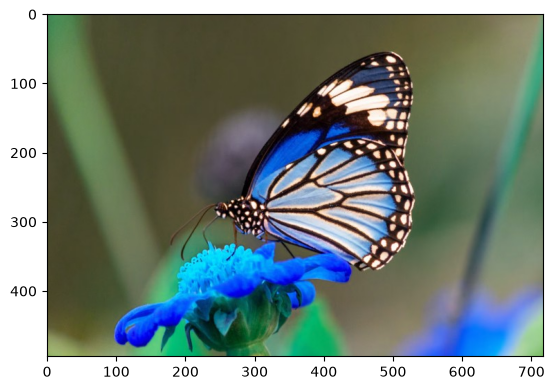

In [11]:
# display the Image (BGR to RGB) 
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) 
plt.imshow(image)




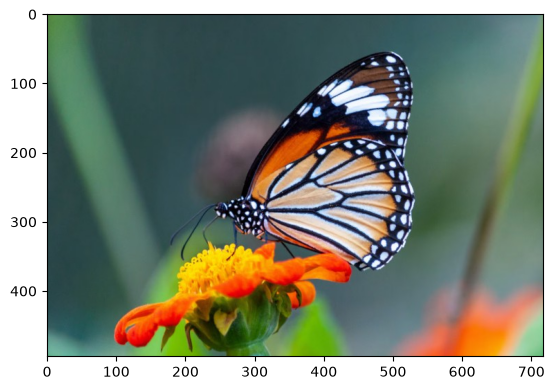

In [12]:
plt.imshow(image_rgb)
plt.show()

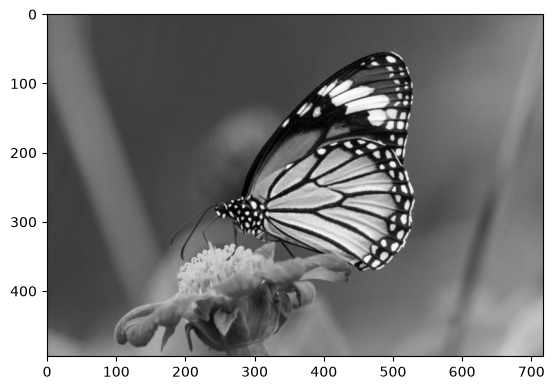

In [13]:
# Convert to Grayscale

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 
plt.imshow(gray, cmap='gray')
plt.show()

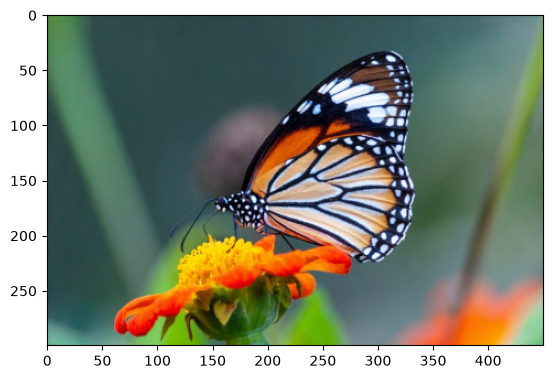

Image Shape: (300, 450, 3)


In [18]:
# Resize 
resized = cv2.resize(image, (450, 300)) # widht and hight 
resized_rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
plt.imshow(resized_rgb)
plt.show()
print("Image Shape:", resized_rgb.shape)

Image Shape: (495, 717, 3)


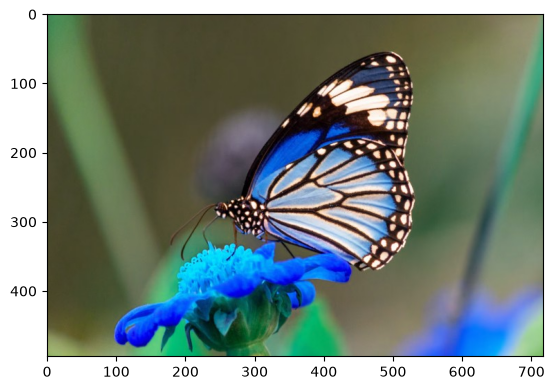

In [19]:
plt.imshow(image)
print("Image Shape:", image.shape)


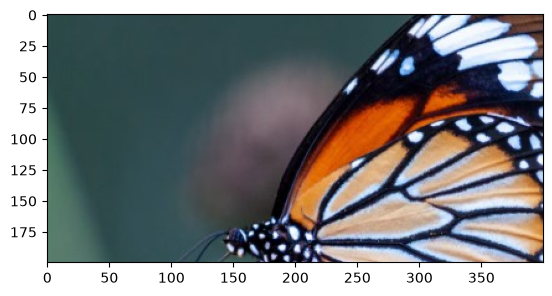

In [23]:
crop = image[100:300, 100:500]
crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
plt.imshow(crop_rgb)
plt.show()

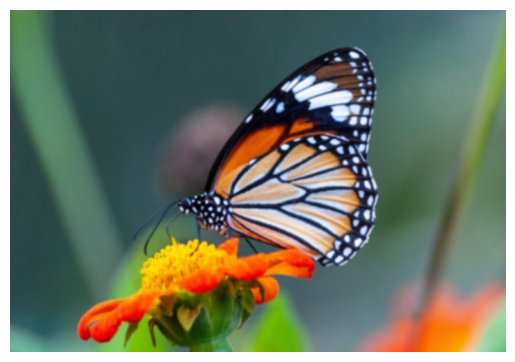

In [25]:
blur = cv2.GaussianBlur(image, (5,5), 0)
blur_rgb = cv2.cvtColor(blur, cv2.COLOR_BGR2RGB) 
plt.imshow(blur_rgb) 
plt.axis("off")
plt.show()


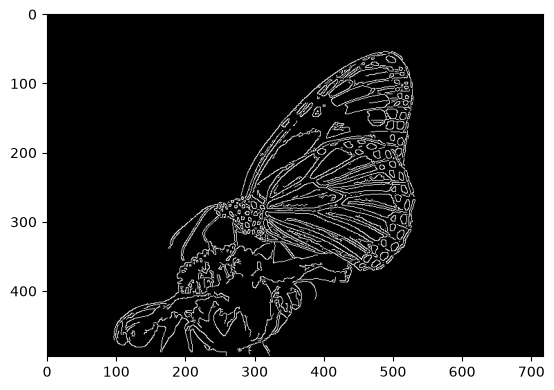

In [28]:
edge = cv2.Canny(gray, 50, 150) 
plt.imshow(edge, cmap='gray')
plt.show()

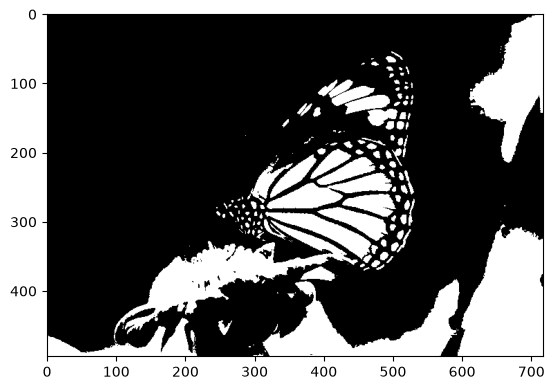

In [29]:
_, threshold = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY) 
plt.imshow(threshold, cmap='gray')
plt.show()

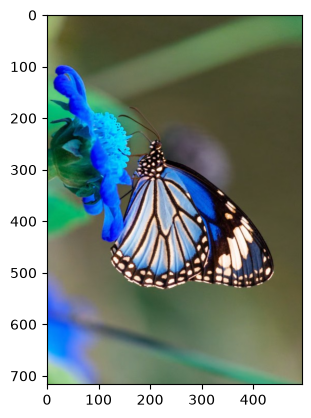

In [30]:
rotated = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE) 
plt.imshow(rotated) 
plt.show()

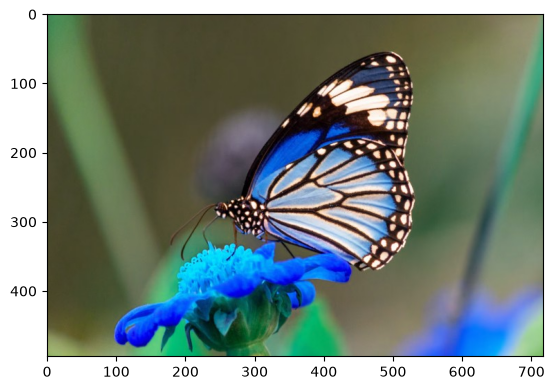

In [31]:
plt.imshow(image) 

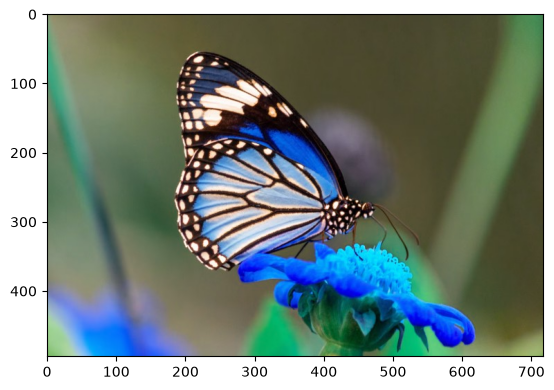

In [33]:
flipped = cv2.flip(image, 1) 
plt.imshow(flipped) 
plt.show()

In [ ]:
input image ---> Image classification Model (Deep Learning) ---> Predicted ouput (Cat /Dog) 

In [ ]:
Classification: 
   1. Binary Classification (cat / dog) *
   2. Multi-Class classification (cat / dog / bird) * 
   3. Multi-label classification (car + road + person)  

In [ ]:
pip install tensorflow

In [38]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing import image 
import numpy as np

model = MobileNetV2(weights="imagenet") 
img = image.load_img('image2.jpg', target_size=(224,224)) 
x = image.img_to_array(img) 
x = np.expand_dims(x, axis=0) 
x = x/255.0 
predictions = model.predict(x) 
print("prdicted :", predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
prdicted : [[1.94905533e-05 5.66239214e-05 6.38519577e-06 3.01023829e-05
  6.37703852e-05 5.17776334e-06 1.01830219e-05 2.16101744e-05
  2.46060335e-05 4.89763988e-05 1.15740886e-05 9.74977047e-06
  5.55522893e-05 3.75173586e-05 1.68489714e-05 4.28503372e-05
  5.76146049e-05 6.37981211e-05 9.75401235e-06 6.90064007e-06
  3.25812616e-05 2.42729766e-05 3.15206453e-05 7.35181902e-06
  5.24935203e-05 5.09819220e-05 4.74883891e-05 3.59530750e-05
  3.48783688e-05 4.23980346e-05 6.30222712e-05 2.17920897e-05
  8.84452747e-05 5.72517383e-05 7.29202875e-05 3.28550595e-05
  5.54959988e-05 2.78779553e-05 2.08241217e-05 1.22680227e-04
  1.34908005e-05 3.21202424e-05 5.75993872e-05 1.40301752e-04
  2.65471208e-05 2.21612245e-05 2.08900401e-05 9.20386374e-05
  2.67573487e-05 9.74358954e-06 1.73435517e-04 1.48600273e-04
  3.38858408e-05 2.21913197e-05 4.70710474e-05 1.13453016e-05
  2.40580521e-05 5.02264702e-05 3.03420638e-05 2.75008206e-05
  2.38987341e-05 5.5355

In [40]:
from tensorflow.keras.applications.mobilenet_v2 import decode_predictions
results = decode_predictions(predictions, top=5)[0]
for class_id, class_name, probability in results:
    print(f"{class_name}: {probability * 100:.2f}%")

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
Egyptian_cat: 73.75%
tabby: 13.43%
tiger_cat: 6.39%
lynx: 0.81%
Persian_cat: 0.38%


In [42]:
import tensorflow as tf
dataset_path = r"data/"
dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=(224, 224),
    batch_size=32
)

print(dataset.class_names)

Found 2527 files belonging to 6 classes.
['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [43]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(6, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
history = model.fit(
    dataset,
    epochs=10
)

Epoch 1/10


C:\Users\ramar\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


12/79 ━━━━━━━━━━━━━━━━━━━━ 1:07 1s/step - accuracy: 0.3203 - loss: 1.7445

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

img = image.load_img(
    "waste.jpg",
    target_size=(224, 224)
)

img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

prediction = model.predict(img_array)

class_id = np.argmax(prediction[0])

print("Predicted Waste:", dataset.class_names[class_id])